# 06 — Convolution and Filtering

Spatial filters combine nearby pixels using a small kernel. Understanding kernel orientation, boundary extension, and numerical types is essential for reproducible results.

## Learning objectives
- Derive discrete 2D convolution and correlation.
- Implement filtering with NumPy loops and a 3×3 mean kernel.
- Compare padding conventions and signed floating-point results.
- Verify OpenCV `filter2D` and SciPy convolution using explicit conventions.

Run independently with `skimage.data.camera()`. This lesson covers smoothing and generic asymmetric kernels; Sobel operators and edge detection are reserved for a later lesson.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
np.set_printoptions(precision=4, suppress=True)

## 1. Mathematical foundations

For an odd kernel $K$ of size $(2a+1)\times(2b+1)$, centered correlation is

$$R[i,j]=\sum_{u=-a}^{a}\sum_{v=-b}^{b}K[u+a,v+b]I[i+u,j+v].$$

Convolution reverses the sample offsets:

$$(I*K)[i,j]=\sum_{u=-a}^{a}\sum_{v=-b}^{b}K[u+a,v+b]I[i-u,j-v].$$

Equivalently, convolution is correlation with both kernel axes flipped. For a centrosymmetric mean or Gaussian kernel the results coincide. `cv2.filter2D` performs correlation despite its name.

The $3\times3$ mean kernel is

$$K=\frac{1}{9}\begin{bmatrix}1&1&1\\1&1&1\\1&1&1\end{bmatrix}.$$

Its coefficients sum to one, preserving constant regions when the boundary extension is also constant-preserving. Zero padding violates that condition near a nonzero image boundary. Filtering should use floats before optional clipping/rounding to uint8.

Manual/OpenCV max absolute error: 3.3306690738754696e-16


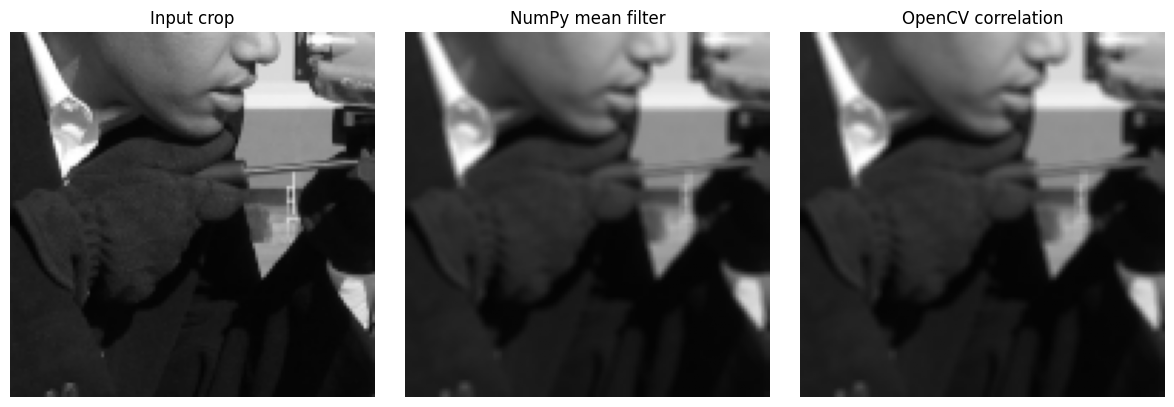

In [2]:
image = data.camera()
image_float = image.astype(np.float64) / 255.0
mean_kernel = np.ones((3, 3), dtype=np.float64) / 9

def correlate2d_manual(array, kernel, padding='reflect'):
    array = np.asarray(array, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    if array.ndim != 2 or kernel.ndim != 2 or any(size % 2 == 0 for size in kernel.shape):
        raise ValueError('Expected a 2D image and an odd-sized 2D kernel')
    pad_y, pad_x = kernel.shape[0] // 2, kernel.shape[1] // 2
    padded = np.pad(array, ((pad_y, pad_y), (pad_x, pad_x)), mode=padding)
    result = np.empty_like(array)
    for row in range(array.shape[0]):
        for col in range(array.shape[1]):
            patch = padded[row:row + kernel.shape[0], col:col + kernel.shape[1]]
            result[row, col] = np.sum(patch * kernel)
    return result

# Use a crop to keep the transparent loop implementation inexpensive.
crop = image_float[160:288, 160:288]
manual_mean = correlate2d_manual(crop, mean_kernel)
cv_mean = cv2.filter2D(crop, cv2.CV_64F, mean_kernel, borderType=cv2.BORDER_REFLECT_101)
print('Manual/OpenCV max absolute error:', np.max(np.abs(manual_mean - cv_mean)))
assert np.allclose(manual_mean, cv_mean, atol=1e-12)
assert np.isclose(mean_kernel.sum(), 1)
assert np.allclose(correlate2d_manual(np.ones((9, 9)), mean_kernel), 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, arr, title in zip(axes, [crop, manual_mean, cv_mean], ['Input crop', 'NumPy mean filter', 'OpenCV correlation']):
    ax.imshow(arr, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Boundary extension is part of the algorithm

NumPy `reflect` excludes the edge sample, matching OpenCV `BORDER_REFLECT_101`. NumPy `symmetric` repeats the edge sample, matching `BORDER_REFLECT`. NumPy `edge` matches `BORDER_REPLICATE`; `constant` with zero fill matches `BORDER_CONSTANT` with zero fill. Similar names across libraries do not guarantee identical behavior.

A constant test image makes zero-padding artifacts easy to isolate. All filters below use the same normalized mean kernel.

constant   [0 0 1 2 3 4 0 0]
edge       [1 1 1 2 3 4 4 4]
reflect    [3 2 1 2 3 4 3 2]
symmetric  [2 1 1 2 3 4 4 3]


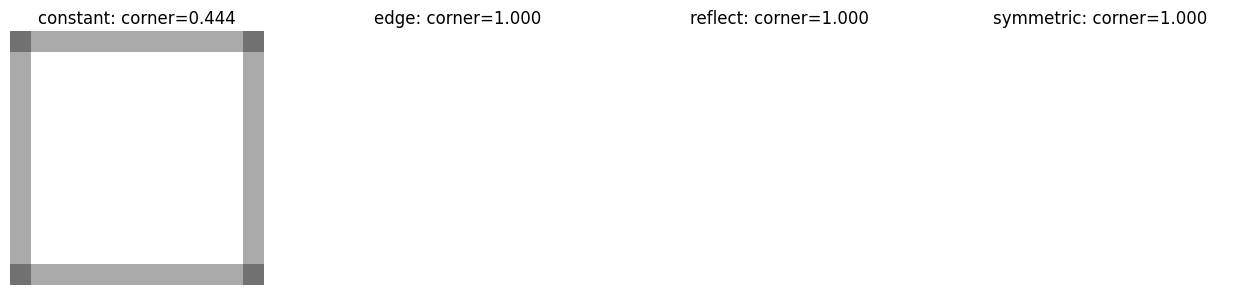

In [3]:
constant = np.ones((12, 12))
padding_pairs = [('constant', cv2.BORDER_CONSTANT), ('edge', cv2.BORDER_REPLICATE),
                 ('reflect', cv2.BORDER_REFLECT_101), ('symmetric', cv2.BORDER_REFLECT)]
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, (mode, border) in zip(axes, padding_pairs):
    result = correlate2d_manual(constant, mean_kernel, mode)
    reference = cv2.filter2D(constant, cv2.CV_64F, mean_kernel, borderType=border)
    assert np.allclose(result, reference)
    ax.imshow(result, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{mode}: corner={result[0, 0]:.3f}')
    ax.axis('off')
plt.tight_layout()
plt.show()

line = np.array([1, 2, 3, 4])
for mode, _ in padding_pairs:
    print(f'{mode:10s}', np.pad(line, 2, mode=mode))

## 3. Correlation versus convolution

A symmetric kernel cannot reveal a kernel-flipping error. Use an asymmetric directional weighting kernel and an impulse instead. The correlation impulse response is flipped relative to the convolution response. SciPy `convolve2d` explicitly implements convolution; zero boundaries make this comparison unambiguous.

Correlation response center:
 [[0.     0.     0.    ]
 [0.5    0.     0.    ]
 [0.3333 0.1667 0.    ]]
Convolution response center:
 [[0.     0.1667 0.3333]
 [0.     0.     0.5   ]
 [0.     0.     0.    ]]


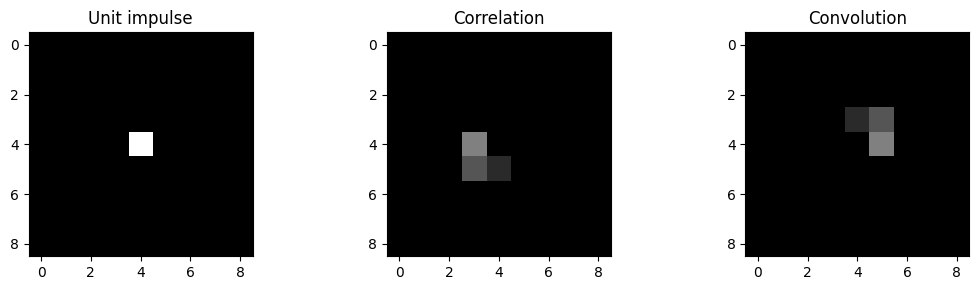

In [4]:
from scipy.signal import convolve2d

asymmetric = np.array([[0, 1, 2], [0, 0, 3], [0, 0, 0]], dtype=float) / 6
impulse = np.zeros((9, 9))
impulse[4, 4] = 1
correlation = correlate2d_manual(impulse, asymmetric, 'constant')
convolution = correlate2d_manual(impulse, asymmetric[::-1, ::-1], 'constant')
scipy_convolution = convolve2d(impulse, asymmetric, mode='same', boundary='fill', fillvalue=0)
cv_correlation = cv2.filter2D(impulse, cv2.CV_64F, asymmetric, borderType=cv2.BORDER_CONSTANT)
assert np.allclose(convolution, scipy_convolution)
assert np.allclose(correlation, cv_correlation)
assert not np.allclose(convolution, correlation)
print('Correlation response center:\n', correlation[3:6, 3:6])
print('Convolution response center:\n', convolution[3:6, 3:6])
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, arr, title in zip(axes, [impulse, correlation, convolution], ['Unit impulse', 'Correlation', 'Convolution']):
    ax.imshow(arr, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(0, 9, 2))
    ax.set_yticks(range(0, 9, 2))
plt.tight_layout()
plt.show()

## 4. Noise reduction versus detail loss

For independent zero-mean noise with variance $\sigma_n^2$, a linear weighted sum has variance

$$\operatorname{Var}(n_{out})=\sigma_n^2\sum_{u,v}K[u,v]^2.$$

For a normalized 3×3 mean filter, the standard-deviation ratio is $1/3$ in the interior. This assumes independent noise and says nothing about scene-detail preservation. Use an unclipped additive-noise model here to keep that assumption intact; display clipping does not change the stored arrays. Larger windows smooth more strongly but also average across finer structures.

Interior noise std ratio: 0.3342878756395879
Predicted std ratio: 0.3333333333333333
Noisy | RMSE against original: 0.06007522605760423
Mean 3×3 | RMSE against original: 0.03923090338384786
Mean 9×9 | RMSE against original: 0.06375253639925482


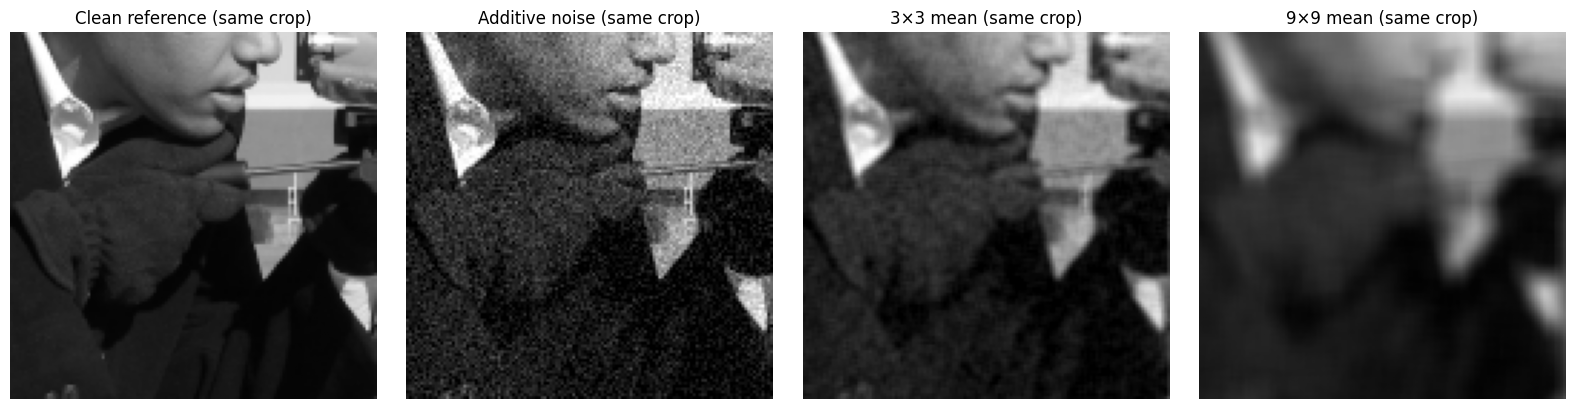

In [5]:
rng = np.random.default_rng(42)
noise = rng.normal(0, 0.06, image_float.shape)
noisy = image_float + noise
filtered3 = cv2.filter2D(noisy, cv2.CV_64F, mean_kernel, borderType=cv2.BORDER_REFLECT_101)
kernel9 = np.ones((9, 9)) / 81
filtered9 = cv2.filter2D(noisy, cv2.CV_64F, kernel9, borderType=cv2.BORDER_REFLECT_101)
filtered_noise = cv2.filter2D(noise, cv2.CV_64F, mean_kernel, borderType=cv2.BORDER_REFLECT_101)
print('Interior noise std ratio:', filtered_noise[1:-1, 1:-1].std() / noise[1:-1, 1:-1].std())
print('Predicted std ratio:', np.sqrt(np.sum(mean_kernel ** 2)))
for name, arr in [('Noisy', noisy), ('Mean 3×3', filtered3), ('Mean 9×9', filtered9)]:
    print(name, '| RMSE against original:', np.sqrt(np.mean((arr - image_float) ** 2)))
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, arr, title in zip(axes, [image_float, noisy, filtered3, filtered9],
                         ['Clean reference', 'Additive noise', '3×3 mean', '9×9 mean']):
    ax.imshow(arr[160:288, 160:288], cmap='gray', vmin=0, vmax=1)
    ax.set_title(title + ' (same crop)')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Interpretation, limitations, and review

The numerical comparisons use identical dtypes, kernels, and boundaries. Agreement in the image interior alone would not verify padding. A larger kernel may reduce noise variance while increasing total reconstruction error because it removes real image structure. Reflective padding is a modeling choice, not a universal description of pixels outside the field of view.

Direct loops cost $O(HWk_hk_w)$ operations and are educational rather than fast. A separable mean filter can use horizontal and vertical 1D passes; this idea will also apply to Gaussian smoothing. Float outputs retain fractional and potentially signed results; clipping to uint8 should be a final, explicit decision.

1. Under what kernel symmetry do correlation and convolution coincide?
2. Why does zero padding darken a constant image at its edges?
3. Predict the interior noise standard-deviation ratio for a 9×9 mean kernel.
4. Why can RMSE worsen when the smoothing window grows?
5. How would you test a filter implementation so that both orientation and boundaries are exercised?

## Summary and connection

Convolution is a core Signal Processing operation: spatial averaging suppresses rapidly varying components. CNN layers conventionally implement cross-correlation with learned kernels. Explicit shape, boundary, and dtype choices are as important for these layers as for classical filters. The existing Gaussian-blur experiment in notebook 07 explores another smoothing kernel.